# Comparing microphysics and moments between two products

The estimator decides the answer. When product B is built to detect 75 % of A's small
particles, the mean distribution over the counted seconds returns 0.747, while the median of
co-positive cell ratios returns 1.667, exactly the ratio of the two products' one-count quanta and
blind to detection. With the right estimator the two products' moments agree to within a few per
cent (*N* ratio 0.945, Z difference +0.12 dB). On a probe-rendered flight with a known answer, the
package's bulk-quantity functions recover Nt at 0.779 of the truth and LWC at 1.297, and the gap is
the optics, not the arithmetic.

**A note on the references.** The papers cited in this notebook are the ones its author used and learned from, and each contains everything this notebook takes from it. They are not the papers that first derived these definitions.

**What you get**

- An estimator rule for comparing two products, with the two diagnostics (one-count quantum ratio,
  positive-cell occupancy ratio) that split a difference into sample volume and detection.
- Which liquid-cloud properties of Gupta et al. (2021) can be computed from a size distribution
  and which cannot, with the drizzle concentration computed per product.
- Nt, LWC, MVD and the drizzle concentration from the package's own functions, each set beside
  the truth, with Garwood counting intervals.

> **Every number in this notebook is synthetic.** Two flights, their temperature record and two
> processings of one imaging probe are drawn from a fixed-seed random-number generator in
> section 1; section 5's flight is rendered by the package's own synthetic-probe generator. No
> data file is read.

**The problem.** Two products of one probe -- two processing chains, or a product and its
reprocessing -- are compared through their moments: total concentration *N*, mean and
median-volume diameter, effective diameter, water content and the sixth moment *Z*. Three choices
decide whether that comparison means anything, and none of them is in the processing code:

1. **The estimator.** The moment of the *mean distribution over the counted seconds* (sum over
   sum) measures what each product detected. The *median of per-cell ratios over cells where both
   products are positive* looks robust, but in sparse bins it measures the ratio of the two
   products' one-count quanta (their sample volumes) and is blind to a difference in detection.
2. **The phase.** A liquid water content is only meaningful on liquid seconds and an ice mass
   relation only on ice seconds; a flight-wide figure mixes them. The per-second check is in
   [10_check_the_phase_assumption.ipynb](../5_data_quality/10_check_the_phase_assumption.ipynb).
3. **The units.** The sixth moment spans orders of magnitude, so it is reported in dBZ,
   $10\log_{10}(Z / 1\,\mathrm{mm^6\,m^{-3}})$, and a difference between products in dB, never as a linear ratio.

The sections: (1) synthetic data; (2) the moment definitions; (3) the estimator lesson; (4) the
liquid-cloud properties of Gupta et al. (2021); (5) from N(D) to bulk quantities on a flight with a
known answer, where every figure is set beside the truth; (6) the checklist for your own data. The
per-second phase strip is worked in [10_check_the_phase_assumption.ipynb](../5_data_quality/10_check_the_phase_assumption.ipynb), section 7.

**Before this:** [06_read_products](../1_getting_started/06_read_products.ipynb) (Reading the output files). **Related:** [07_gamma_fitting](07_gamma_fitting.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/6_science/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

## 0. Size-distribution notation: $N_T$, $\Delta N_i$ and $n(D) = \mathrm{d}N/\mathrm{d}D$

A probe counts particles in a sampled volume and sorts them into size bins $i$ with lower and upper
edges $D_i^-$, $D_i^+$, width $\Delta D_i = D_i^+ - D_i^-$ (not constant across bins) and a
representative size $D_i$ (the bin midpoint).

| Symbol | Name | Units | Meaning |
|---|---|---|---|
| $N_T$ | total number concentration | cm$^{-3}$ | all particles per unit volume of air |
| $\Delta N_i$ | bin concentration | cm$^{-3}$ | particles per unit volume in bin $i$ |
| $n(D) \equiv \mathrm{d}N/\mathrm{d}D$ | number distribution function | cm$^{-3}\,\mu$m$^{-1}$ | particles per unit volume *per unit diameter* |
| $f(D)$ | probability density of size | $\mu$m$^{-1}$ | $n(D)/N_T$; integrates to 1 |

The measured estimate of $n(D)$ in bin $i$ is the bin concentration divided by the bin width,

$$n(D_i) \approx \frac{\Delta N_i}{\Delta D_i} \quad\Longleftrightarrow\quad \Delta N_i \approx n(D_i)\,\Delta D_i ,$$

which is why a code that stores `dNdD` recovers the per-bin concentration as `dNdD * bin_width`.
The total follows as a sum over bins or an integral over size:

$$N_T = \sum_i \Delta N_i = \int_0^\infty n(D)\,\mathrm{d}D .$$

Integrating $\Delta N_i$ (cm$^{-3}$) over $D$ does *not* give $N_T$; only $n(D)$ is integrated.

*Notation in the literature is not uniform*: some authors write $N(D)$ for what is $n(D)$ here, and
others use $N(D)$ for a per-bin concentration. Read the units: cm$^{-3}\,\mu$m$^{-1}$ is the
distribution function, cm$^{-3}$ is a bin concentration or a total.

**The bulk quantities.** On a binned distribution with per-bin concentration $N(D)$ (the
$\Delta N_i$ above) the sums of a combined microphysics data-set readme (O'Brien et al.,
Table 1) are, summed over the bins from $D_{min}$ to $D_{max}$:

| Quantity | Formula | Source |
|---|---|---|
| Number concentration | $N_c = \sum_{D_{min}}^{D_{max}} N(D)$ | readme Table 1 ($N$ over $D > 3\,\mu$m, $N_c$ over $3 < D < 50\,\mu$m) |
| Drizzle concentration | $N_{c50} = \sum_{D > 50\,\mu\mathrm{m}} N(D)$ | readme variable list, `Nc50` ("integrated over $D > 50\,\mu$m") |
| Liquid water content | $\mathrm{LWC} = \rho_w \sum N(D)\,\frac{\pi}{6} D^3$, $\rho_w = 1$ g cm$^{-3}$ | readme Table 1 (printed without $\rho_w$) |
| Effective radius | $r_e = \dfrac{\sum N(D)\,D^3}{2\sum N(D)\,D^2}$ | readme Table 1 |
| Radar reflectivity factor | $Z = \sum N(D)\,D^6$, reported as $10\log_{10}(Z / 1\,\mathrm{mm^6\,m^{-3}})$ dBZ | readme Table 1; the dBZ unit is the readme's `Z` variable |
| Extinction | $\beta = \sum 2\,N(D)\,\frac{\pi}{4} D^2$ | readme Table 1 |

The effective radius and effective variance are defined by Hansen and Travis (1974, Eqs. 2.53-2.54)
as the cross-section-weighted mean radius and its normalised spread, with $G = \int \pi r^2 n(r)\,\mathrm{d}r$
the geometric cross-section per unit volume:

$$r_{\mathrm{eff}} = \frac{\int r\,\pi r^2 n(r)\,\mathrm{d}r}{\int \pi r^2 n(r)\,\mathrm{d}r}, \qquad v_{\mathrm{eff}} = \frac{1}{G\,r_{\mathrm{eff}}^2}\int (r - r_{\mathrm{eff}})^2\,\pi r^2 n(r)\,\mathrm{d}r .$$

With $D = 2r$ the readme's binned $r_e$ is the discrete form of Eq. (2.53); this notebook's
effective diameter is $D_{\mathrm{eff}} = 2r_e = \sum N D^3 / \sum N D^2$.

**Median volume diameter.** This notebook's $D_{mvd}$ is the diameter that splits the liquid volume
in half, $\int_0^{D_{mvd}} D^3 n(D)\,\mathrm{d}D = \tfrac12 \int_0^\infty D^3 n(D)\,\mathrm{d}D$,
interpolated linearly within the bin where the cumulative volume crosses one half. It is this
notebook's definition; none of the sources above prints it (the readme lists a mean volume radius
$r_v$ without a formula).

The worked example (0b) follows the synthetic flights built in section 1.

**Related definitions (quoted, not computed here).** The papers built on these distributions
use further quantities that this notebook mentions but does not compute. Each is quoted as printed,
with the source's equation number; $h$ is height above cloud base $Z_B$, $\rho_w$ the liquid water
density.

| Quantity | Formula as printed | Source |
|---|---|---|
| LWC from $N_c$ and mean volume radius $R_v$ | $\mathrm{LWC}(h) = \frac{\pi\rho_w}{6}\int_3^{19\,200} D^3 n(D,h)\,\mathrm{d}D = \frac{4}{3}\pi\rho_w N_c(h)\,R_v(h)^3$ | Gupta et al. (2022b), Eq. (3) |
| $R_e$ from $R_v$ | $R_e = k^{-1/3}R_v$, $\;k = \frac{(1+d^2)^3}{(ad^3+1+3d^2)^2}$ ($a$ skewness, $d$ dispersion) | Gupta et al. (2022b), Eq. (2) |
| LWP | LWC integrated over $h$ from $Z_B$ to $Z_T$ (stated in text, no equation number) | Gupta et al. (2022b), Sect. 2.1 |
| Extinction and optical depth $\tau$ | $\beta_{\mathrm{ext}}(h) = \frac{\pi}{4}\int_3^{19\,200} Q_{\mathrm{ext}} D^2 n(D,h)\,\mathrm{d}D$, $\;\tau = \int_{Z_B}^{Z_T}\beta_{\mathrm{ext}}(h)\,\mathrm{d}h$, $Q_{\mathrm{ext}} = 2$ | Gupta et al. (2022b), Eq. (4) |
| Adiabatic LWC | $\mathrm{LWC}_{\mathrm{ad}}(h) = C_w h = \frac{4}{3}\pi\rho_w N_{\mathrm{ad}}(h)\,R_{v\mathrm{ad}}(h)^3$ ($C_w$ condensation rate) | Gupta et al. (2022b), Eq. (5) |
| Adiabatic $\tau$ and LWP | $\tau_{\mathrm{ad}} = \frac{3}{5}\pi Q_{\mathrm{ext}}\left(\frac{3C_w}{4\pi\rho_w}\right)^{2/3}(kN_c)^{1/3}H^{5/3}$, $\;\mathrm{LWP}_{\mathrm{ad}} = \frac{1}{2}C_wH^2 = \frac{5}{9}\rho_w\tau R_e$ ($H$ cloud thickness) | Gupta et al. (2022b), Eq. (6) |
| Precipitation rate $R_p$ | $R_p = \frac{\pi}{6}\int n(D)\,D^3u(D)\,\mathrm{d}D$ over drizzle drops from 50 $\mu$m, $u(D)$ the fall speed (Rogers and Yau, 1989) | Gupta et al. (2022a), Eq. (5) |
| Precipitation susceptibility $S_o$ | $S_o = -\mathrm{d}\ln(R_p)/\mathrm{d}\ln(N_c)$ | Gupta et al. (2022a), Eq. (8) |

Gupta et al. (2022b) also give $R_e$ and the effective variance $V_e$ as Hansen and Travis (1974)
integrals over 3-19 200 $\mu$m (their Eq. 1), the same definitions as above.

In [2]:
"""1. Two synthetic flights at 1 Hz, each seen by two products of one probe."""
import numpy as np

rng = np.random.default_rng(20261003)

# Bin ladder: 40 log-spaced bins from 55 to 3000 um (edges), midpoints in um.
EDGES = np.geomspace(55.0, 3000.0, 41)
MID = np.sqrt(EDGES[:-1] * EDGES[1:])
N_SEC = 3600

# The two products differ in exactly two ways, both invented and both known here:
#   sample volume per second (litres): B's is 60 % of A's, so B's one-count quantum is larger;
#   detection efficiency: B detects 75 % of the particles below 100 um that A detects.
SV_A, SV_B = 25.0, 15.0
EFF_B = np.where(MID < 100.0, 0.75, 1.0)

def true_psd(n_per_l, dm_um, mu=2.0):
    """Gamma-shaped number per bin (per litre) for a total n_per_l and mean diameter dm_um."""
    shape = MID ** mu * np.exp(-(mu + 1.0) * MID / dm_um) * np.diff(EDGES)
    return n_per_l * shape / shape.sum()

def make_flight(name, temp):
    """A flight: in-cloud mask, the true bin concentration ΔN_i per second, and each product's concentration."""
    cloudy = rng.random(N_SEC) < 0.7
    n_tot = np.where(cloudy, rng.lognormal(np.log(0.8), 0.6, N_SEC), 0.0)       # per litre
    dm = np.where(temp < 0.0, 450.0, 160.0) * rng.lognormal(0.0, 0.2, N_SEC)
    truth = np.array([true_psd(n, d) for n, d in zip(n_tot, dm)])               # (sec, bin)
    counts_a = rng.poisson(truth * SV_A)
    counts_b = rng.poisson(truth * SV_B * EFF_B)
    return {"name": name, "temp": temp, "cloudy": cloudy, "truth": truth,
            "conc_a": counts_a / SV_A, "conc_b": counts_b / SV_B,                # per litre per bin
            "counts_a": counts_a, "counts_b": counts_b}

t = np.arange(N_SEC)
temp_warm = 9.0 + 1.5 * np.sin(2 * np.pi * t / 1800) + rng.normal(0, 0.2, N_SEC)
temp_cold = np.where(t < 1800, 3.0, -9.0) + rng.normal(0, 0.4, N_SEC)          # second half sub-zero
warm = make_flight("flight W (all above 0 C)", temp_warm)
cold = make_flight("flight C (half below 0 C)", temp_cold)
print(f"{len(MID)} bins, {N_SEC} s per flight; in-cloud seconds: "
      f"W {warm['cloudy'].sum()}, C {cold['cloudy'].sum()}")

40 bins, 3600 s per flight; in-cloud seconds: W 2493, C 2505


### 0b. The notation worked on flight W

Product A's in-cloud mean distribution on flight W, on section 1's 40 log-spaced bins (55-3000 µm),
whose widths grow with size. The cell below takes $\Delta N_i$, divide by the real bin widths to get
$n(D_i)$, and form $N_T$ as a sum and as a trapezoid integral of $n(D)$.
It draws no random numbers, so sections 2-6 are unchanged. Fitting a gamma form to this $n(D)$ is
worked in [07_gamma_fitting](07_gamma_fitting.ipynb).

In [3]:
"""0b. Delta N_i, n(D_i) = Delta N_i / Delta D_i, and N_T two ways, on flight W (product A)."""
dD_um = np.diff(EDGES)                                          # bin widths, um (non-uniform)
dN = warm["conc_a"][warm["cloudy"]].mean(axis=0) / 1e3          # Delta N_i, cm^-3 per bin
n_D = dN / dD_um                                                # n(D_i) = dN/dD, cm^-3 um^-1
trapezoid = getattr(np, "trapezoid", None) or np.trapz          # numpy >= 2 renamed trapz

nt_sum = dN.sum()                                               # sum_i Delta N_i
nt_int = trapezoid(n_D, MID)                                    # integral of n(D) dD, D_1..D_40
print(f"bin widths: {dD_um[0]:.1f} um (first) to {dD_um[-1]:.1f} um (last)")
print(f"N_T = sum of Delta N_i        {nt_sum:.4e} cm^-3")
print(f"N_T = trapezoid of n(D) dD    {nt_int:.4e} cm^-3")
print(f"integral / sum                {nt_int / nt_sum:.3f}   "
      "(the trapezoid spans midpoint to midpoint, so it misses half of each end bin)")

bin widths: 5.8 um (first) to 285.4 um (last)
N_T = sum of Delta N_i        9.6789e-04 cm^-3
N_T = trapezoid of n(D) dD    9.5777e-04 cm^-3
integral / sum                0.990   (the trapezoid spans midpoint to midpoint, so it misses half of each end bin)


## 2. The moment definitions

Every moment below is taken on one distribution `conc` (per litre, per bin) at the bin
midpoints. Nothing is fitted. LWC assumes liquid spheres of density 1 g cm$^{-3}$; the ice mass uses
the Brown and Francis (1995) relation $m = 7.38\times10^{-11}\,D^{1.9}$ ($D$ in µm, $m$ in g) above 100 µm and
solid ice spheres, $m = 4.82\times10^{-13}\,D^3$, below it, where the power law would exceed a solid sphere's
mass (their eq. 3 and the text after it; their D is the mean of the maximum chord lengths along and
across the array, here the bin midpoint of whatever size definition the distribution uses). *Z* is the
liquid-equivalent sixth moment, uncalibrated, in dBZ. The formulas, with their sources, are in section 0:
$N = \sum N(D)$, $\mathrm{LWC} = \rho_w \sum N(D)\,\frac{\pi}{6}D^3$, $D_{\mathrm{eff}} = \sum N D^3 / \sum N D^2 = 2r_e$,
$Z = \sum N(D)\,D^6$ (O'Brien et al. readme, Table 1) and the median volume diameter $D_{mvd}$ (this notebook's definition).

In [4]:
"""2. Moments of one size distribution."""
def moments(conc):
    """N (L^-1), D_mean, D_mvd, D_eff (um), LWC and IWC (g m^-3), Z (dBZ) of one distribution."""
    conc = np.asarray(conc, dtype=float)
    n = conc.sum()
    if n <= 0:
        return dict(N=0.0, D_mean=np.nan, D_mvd=np.nan, D_eff=np.nan, LWC=0.0, IWC=0.0, Z_dBZ=np.nan)
    per_m3 = conc * 1e3
    m3 = per_m3 * MID ** 3
    cum = np.cumsum(m3) / m3.sum()
    k = int(np.searchsorted(cum, 0.5))                       # bin in which half the volume is crossed
    lo = cum[k - 1] if k else 0.0
    d_mvd = EDGES[k] + (0.5 - lo) / (cum[k] - lo) * (EDGES[k + 1] - EDGES[k])
    lwc = (np.pi / 6.0) * 1.0 * np.sum(per_m3 * (MID * 1e-4) ** 3)                  # g m^-3
    m_ice = np.where(MID < 100.0, 4.82e-13 * MID ** 3, 7.38e-11 * MID ** 1.9)     # g; B&F95 eq. 3
    iwc = np.sum(per_m3 * m_ice)                                                    # g m^-3
    z = np.sum(per_m3 * (MID * 1e-3) ** 6)                                          # mm^6 m^-3
    return dict(N=n, D_mean=np.sum(conc * MID) / n, D_mvd=d_mvd,
                D_eff=np.sum(conc * MID ** 3) / np.sum(conc * MID ** 2),
                LWC=lwc, IWC=iwc, Z_dBZ=10 * np.log10(z) if z > 0 else np.nan)

for k, v in moments(warm["truth"][warm["cloudy"]].mean(axis=0)).items():
    print(f"{k:7s} {v:10.4g}")

N           0.9688
D_mean       174.8
D_mvd        337.1
D_eff        293.6
LWC        0.00596
IWC       0.001632
Z_dBZ      -0.1027


## 3. The estimator lesson

Product B detects 75 % of the small particles that A does, by construction, and nothing else
differs. The two estimators below are computed over flight W's in-cloud seconds.

* **Mean distribution (sum over sum).** Average each product's distribution over the counted
  seconds, then take the moment. The small-bin ratio should come back near 0.75.
* **Co-positive cell median.** For each (second, bin) cell where both products counted at least
  one particle, take B/A, then the median. In a sparse bin a positive cell is usually one count,
  so the cell ratio is the ratio of the one-count quanta, SV_A / SV_B, whatever the detection.

Two diagnostics split a difference into its parts: the **one-count quantum ratio** (what one
particle is worth in each product) and the **positive-cell occupancy ratio** (how often each
product sees anything at all in a cell).

In [5]:
"""3. Mean distribution versus co-positive cell median, small bins only (< 100 um)."""
sel = warm["cloudy"]
small = MID < 100.0
a, b = warm["conc_a"][sel][:, small], warm["conc_b"][sel][:, small]
pos_a, pos_b = warm["counts_a"][sel][:, small] > 0, warm["counts_b"][sel][:, small] > 0

mean_ratio = b.sum() / a.sum()
both = pos_a & pos_b
cell_median = np.median(b[both] / a[both])
quantum_ratio = (1 / SV_B) / (1 / SV_A)
occupancy_ratio = pos_b.mean() / pos_a.mean()

print(f"true detection ratio B/A (built in)       {EFF_B[small][0]:.2f}")
print(f"mean-distribution ratio B/A               {mean_ratio:.3f}")
print(f"co-positive cell median B/A               {cell_median:.3f}   ({both.sum()} cells)")
print(f"one-count quantum ratio B/A               {quantum_ratio:.3f}")
print(f"positive-cell occupancy ratio B/A         {occupancy_ratio:.3f}")

true detection ratio B/A (built in)       0.75
mean-distribution ratio B/A               0.747
co-positive cell median B/A               1.667   (2986 cells)
one-count quantum ratio B/A               1.667
positive-cell occupancy ratio B/A         0.588


The mean-distribution ratio recovers the built-in detection difference. The cell median does
not: it is pulled toward the quantum ratio, so it reports the two sample volumes rather than what
either product detected. The occupancy ratio carries the detection difference together with the
sample-volume difference. Use the mean distribution for every headline figure; if the cell median
is shown at all, label it "co-positive cell ratio" and set the quantum ratio beside it.

The same estimator, applied to the full moments of flight W:

In [6]:
"""3b. Flight W's moments from each product's mean distribution; Z difference in dB."""
ma = moments(warm["conc_a"][sel].mean(axis=0))
mb = moments(warm["conc_b"][sel].mean(axis=0))
print(f"{'moment':8s} {'A':>10s} {'B':>10s}  B vs A")
for k in ("N", "D_mean", "D_mvd", "D_eff", "LWC"):
    print(f"{k:8s} {ma[k]:10.4g} {mb[k]:10.4g}  ratio {mb[k] / ma[k]:.3f}")
print(f"{'Z_dBZ':8s} {ma['Z_dBZ']:10.2f} {mb['Z_dBZ']:10.2f}  difference {mb['Z_dBZ'] - ma['Z_dBZ']:+.2f} dB")

moment            A          B  B vs A
N            0.9679     0.9143  ratio 0.945
D_mean        174.7      181.4  ratio 1.038
D_mvd         335.3      337.3  ratio 1.006
D_eff         291.8      295.2  ratio 1.011
LWC        0.005903   0.005983  ratio 1.014
Z_dBZ         -0.45      -0.33  difference +0.12 dB


Per-second phase classes and per-phase moments of these two products: [10_check_the_phase_assumption.ipynb](../5_data_quality/10_check_the_phase_assumption.ipynb), section 7.


## 4. Liquid-cloud properties (Gupta et al. 2021)

**Takeaway.** Of the liquid-cloud properties in Gupta et al. (2021, *Atmos. Chem. Phys.*, 21,
4615-4635, doi:10.5194/acp-21-4615-2021), one comes with a definition that can be computed from a
size distribution as printed: the **drizzle concentration**, "droplets with diameters larger than
50 µm", quoted in L$^{-1}$. Its number concentration *N*c, effective radius *R*e and LWC are named,
with their source (the CAS and 2D-S distributions merged at 50 µm into one 1 Hz distribution),
but the paper prints no formula for them; the formulas the combined microphysics data set uses for
them are in O'Brien et al.'s readme, Table 1, quoted in section 0, and the paper's only numbered equation, Eq. (1), is
the cloud-top entrainment-instability criterion, which needs thermodynamic profiles rather than a
size distribution. This section therefore computes the drizzle concentration from the paper's cut
and *R*e with the readme's formula, $r_e = \sum N D^3 / (2\sum N D^2)$, the binned form of
Hansen and Travis (1974) Eq. (2.53). On this notebook's imaging-probe ladder (55 µm and up) every
bin is above the cut, so the drizzle concentration equals *N*; on section 5's ladder (from 5 µm)
the cut separates cloud from drizzle and is checked against the truth.

| Property (paper's unit) | What the paper prints | Here |
|---|---|---|
| Drizzle concentration (L$^{-1}$) | "droplets with diameters larger than 50 µm" (Sect. 3.4, p. 8; no equation number) | computed per product; how a bin straddling 50 µm is treated is not stated, so only bins wholly above it count |
| Size-distribution merge | CAS and 2D-S merged at 50 µm into one 1 Hz distribution, "used to calculate Nc, Re, and LWC" (p. 4) | not applied: this demo has one imaging probe and no CAS |
| Normalized height *Z*N | (*Z* − *Z*B)/(*Z*T − *Z*B), 0 at cloud base, 1 at cloud top, in bins of 0.1 (p. 8) | skipped: the synthetic flights carry no altitude, cloud base or cloud top, so drizzle concentration cannot be plotted against *Z*N here |
| *N*c (cm$^{-3}$) | from the merged CAS + 2D-S distribution; readme Table 1: $N_c = \sum N(D)$ over $3 < D < 50\,\mu$m | skipped: this demo has no droplet-probe distribution below 55 µm |
| *R*e (µm) | from the merged distribution; readme Table 1: $r_e = \sum N D^3 / (2\sum N D^2)$ (Hansen and Travis 1974, Eq. 2.53) | section 2's *D*eff / 2, the same ratio |
| LWC (g m$^{-3}$) | from the merged distribution; readme Table 1: $\rho_w \sum N(D)\,\frac{\pi}{6}D^3$ | section 2's LWC (liquid spheres, 1 g cm$^{-3}$), compared in section 3b; on section 5's flight, `arrayprobe.lwc.lwc_calc`, the port of UIOOPS's `lwc_calc.m` |
| Cloud-sample rule | *N*c > 10 cm$^{-3}$ and bulk (hot-wire) LWC > 0.05 g m$^{-3}$, 1 Hz | skipped: needs a droplet probe and a bulk LWC probe; the synthetic flights carry an in-cloud mask instead |
| LWC / adiabatic LWC | adiabatic LWC used as a mixing measure; no formula | skipped: needs temperature and pressure profiles |
| Eq. (1), CTEI | Δθe > k (Lv / Cp) ΔqT | skipped: not a size-distribution property |

drizzle concentration (D > 50 um): A 0.968 L^-1, B 0.914 L^-1, B/A 0.945
Re (section 2 definition):        A 145.9 um,  B 147.6 um,  B - A +1.7 um


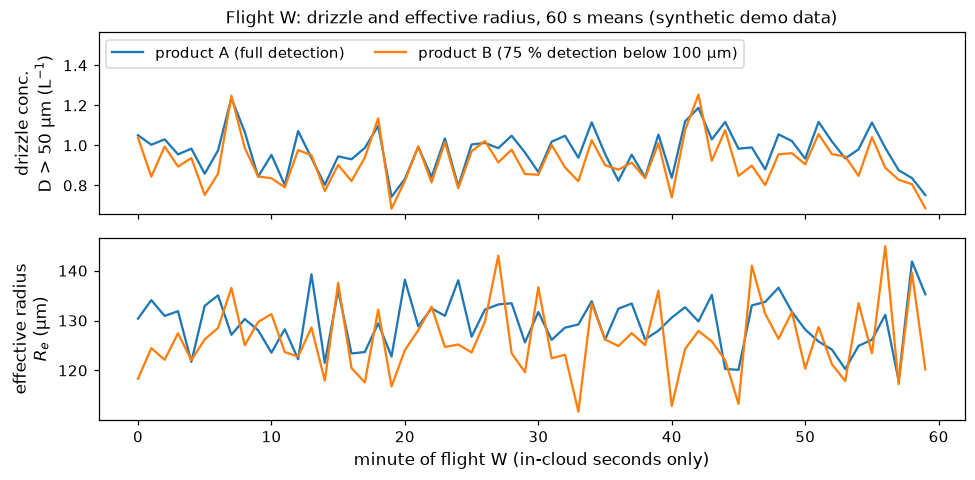

In [7]:
"""4. Drizzle concentration and Re on flight W, per product: 60 s means and the leg means."""
import matplotlib.pyplot as plt

DRIZZLE_CUT_UM = 50.0


def drizzle_concentration(conc, edges=EDGES):
    """Drizzle concentration (L^-1 when conc is per litre per bin), over bins wholly above 50 um.

    Gupta et al. (2021), Sect. 3.4 (p. 8), no equation number (the paper prints none): drizzle is
    "droplets with diameters larger than 50 um", quoted in L^-1. The paper does not say how a
    bin straddling 50 um is treated; here a bin counts only if its lower edge is >= 50 um.
    """
    conc = np.asarray(conc, dtype=float)
    return conc[..., np.asarray(edges)[:-1] >= DRIZZLE_CUT_UM].sum(axis=-1)


def effective_radius_um(conc, mid=MID):
    """Re (um) as this notebook's section 2 D_eff halved: sum(conc D^3) / sum(conc D^2) / 2.

    No equation number: Gupta et al. (2021) name Re but print no formula, so this is the
    notebook's own definition and is labelled so wherever it is shown.
    """
    conc = np.asarray(conc, dtype=float)
    with np.errstate(invalid="ignore", divide="ignore"):
        return (conc * mid ** 3).sum(axis=-1) / (conc * mid ** 2).sum(axis=-1) / 2.0


sel = warm["cloudy"]
dz = {p: drizzle_concentration(warm[f"conc_{p}"]) for p in ("a", "b")}
re_ = {p: effective_radius_um(warm[f"conc_{p}"]) for p in ("a", "b")}


def minute_means(x):
    x = np.where(sel, x, np.nan).reshape(-1, 60)
    return np.nanmean(x, axis=1)


fig, ax = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
for p, lab in (("a", "product A (full detection)"),
               ("b", "product B (75 % detection below 100 µm)")):
    ax[0].plot(minute_means(dz[p]), label=lab)
    ax[1].plot(minute_means(re_[p]), label=lab)
ax[0].set_ylabel("drizzle conc.\nD > 50 µm (L$^{-1}$)")
ax[1].set_ylabel("effective radius\n$R_e$ (µm)")
ax[1].set_xlabel("minute of flight W (in-cloud seconds only)")
ax[0].set_title("Flight W: drizzle and effective radius, 60 s means (synthetic demo data)",
                fontsize=11)
lo, hi = ax[0].get_ylim()
ax[0].set_ylim(lo, hi + 0.45 * (hi - lo))   # display only: room for the legend
ax[0].legend(fontsize=10, ncol=2, loc="upper left")
fig.tight_layout()
plt.show()

# Leg means from each product's mean distribution (section 3's estimator), and B against A.
mean_a, mean_b = warm["conc_a"][sel].mean(axis=0), warm["conc_b"][sel].mean(axis=0)
dz_a, dz_b = drizzle_concentration(mean_a), drizzle_concentration(mean_b)
re_a, re_b = effective_radius_um(mean_a), effective_radius_um(mean_b)
print(f"drizzle concentration (D > 50 um): A {dz_a:.3f} L^-1, B {dz_b:.3f} L^-1, B/A {dz_b / dz_a:.3f}")
print(f"Re (section 2 definition):        A {re_a:.1f} um,  B {re_b:.1f} um,  B - A {re_b - re_a:+.1f} um")


*Figure 1. Flight W (synthetic demo data), in-cloud seconds only, 60 s means. Top: drizzle concentration, droplets above 50 µm, in L⁻¹. Bottom: effective radius R_e (µm), half the effective diameter defined in section 2. Product B detects 75 % of the particles below 100 µm that product A detects; the two lines differ only by that and by counting noise.*

## 5. From N(D) to bulk quantities on a flight with a known answer

**Takeaway.** On a probe-rendered synthetic flight whose every droplet is known, the package's
own bulk-quantity functions recover the truth to within what the probe can see: total number
concentration, liquid water content (`arrayprobe.lwc`, the port of UIOOPS's `lwc_calc.m`), median
volume diameter (SODA-2's `mvdiam`) and section 4's drizzle
concentration, each set beside the true value, with Garwood counting intervals on the counts. The
differences come from the optics (depth of field, clipping at the array ends, few-pixel small
droplets), not from the arithmetic. Section 2 defined the moments for comparing two products;
this section checks the same quantities against a truth.


In [8]:
"""5. Imports for the known-truth flight (the probe renderer and its harness)."""
import sys
import tempfile

import numpy as np
import xarray as xr   # reads the output files; an example-only dependency, see examples/README.md

from arrayprobe.tools import synthetic_truth as st

sys.path.insert(0, "scripts")
import truth_harness as th  # noqa: E402

### A flight with a known answer

Ten seconds of liquid droplets drawn from a lognormal distribution (median 60 um,
geometric standard deviation 1.8, 15-500 um), spread uniformly through the depth of field
and across the array, at 130 m/s. The generator renders each droplet's diffraction image
as the probe would see it, so out-of-focus droplets image larger or as rings, and droplets
near an array end are clipped. The chain has to cope with all of that.

In [9]:
tmp = tempfile.TemporaryDirectory()
root = Path(tmp.name)
FLIGHT = st.FlightSpec(n_seconds=10, rate_per_s=600.0, seed=3,
                       psd=st.PSD(kind="lognormal", median_um=60.0, gsd=1.8))
raw, manifest = th.build(root / "flight", FLIGHT)
drop = manifest.array("kind") == "droplet"
d_true_um = manifest.array("d0_um")[drop]
volume_cm3 = manifest.sampled_volume_m3() * 1e6
print(f"{d_true_um.size} droplets drawn in {volume_cm3:.1f} cm^3 of sampled air")

5860 droplets drawn in 203112.0 cm^3 of sampled air


### The size distribution

The v3.5 engine decodes, frames and bins the raw file. The project switch `SOCRATES`
selects UIOOPS's 10 um 2D-S bin ladder; the first 128 of its bins span 5 um to 1.285 mm.

In [10]:
paths = th.run_v35(raw, root / "v35", FLIGHT)
# mask_and_scale=False: the raw stored values, as netCDF4's set_auto_mask(False) gives them
with xr.open_dataset(paths["sd"], mask_and_scale=False, decode_times=False) as ds:
    conc = np.nan_to_num(np.asarray(ds["conc_minR"][:], float))[:, : th.NB]   # cm^-4
    count = np.nan_to_num(np.asarray(ds["count"][:], float))[:, : th.NB]
    mid_mm = np.asarray(ds["bin_mid"][:], float)[: th.NB]
    dd_mm = np.asarray(ds["bin_dD"][:], float)[: th.NB]
    t = np.asarray(ds["time"][:], float)
in_flight = np.isin((t // 10000) * 3600 + (t // 100 % 100) * 60 + t % 100,
                    th.flight_seconds(FLIGHT))
conc, count = conc[in_flight], count[in_flight]
edges_um = th.KK_MM * 1000.0
per_bin = conc.mean(axis=0) * dd_mm / 10.0          # cm^-3 per bin, flight mean
print(f"{conc.shape[0]} seconds, {int(count.sum())} particles counted, {th.NB} bins")

10 seconds, 1161 particles counted, 128 bins


### Total number concentration, Nt

The zeroth moment: concentration summed over bins. The truth is the droplets drawn above
the first used bin edge, divided by the volume they were drawn in.

In [11]:
lower_um = 25.0              # below ~2.5 pixels a 10 um probe does not size reliably
use = edges_um[:-1] >= lower_um
nt = per_bin[use].sum()
nt_true = np.sum(d_true_um >= lower_um) / volume_cm3
print(f"Nt (D >= {lower_um:g} um): recovered {nt:.3f} cm^-3, true {nt_true:.3f} cm^-3, "
      f"ratio {nt / nt_true:.3f}")

Nt (D >= 25 um): recovered 0.021 cm^-3, true 0.027 cm^-3, ratio 0.779


### Liquid water content

`arrayprobe.lwc.lwc_calc` is the port of UIOOPS's `lwc_calc.m`: each bin's concentration
times the volume of a sphere at the bin's midpoint, times the density of water.

In [12]:
from arrayprobe.lwc import lwc_calc

lwc = lwc_calc([np.where(use, per_bin, 0.0)], mid_mm * 1000.0)[0]
d_use = d_true_um[d_true_um >= lower_um]
lwc_true = np.sum(np.pi / 6 * (d_use * 1e-4) ** 3) / volume_cm3 * 1e6   # g m^-3
print(f"LWC: recovered {lwc:.4f} g m^-3, true {lwc_true:.4f} g m^-3, ratio {lwc / lwc_true:.3f}")

LWC: recovered 0.0187 g m^-3, true 0.0145 g m^-3, ratio 1.297


LWC weights each droplet by $D^3$, so the few largest droplets dominate it and its counting
uncertainty is much larger than Nt's.

### Median volume diameter

`arrayprobe_soda2.export_ascii.mvdiam` is the port of SODA-2's `mvdiam.pro`: the diameter
below which half the liquid volume lies, interpolated on the cumulative volume.

In [13]:
from arrayprobe_soda2.export_ascii import mvdiam

conc_m3 = np.where(use, per_bin, 0.0) * 1e6                  # cm^-3 -> m^-3
mvd = float(mvdiam(conc_m3[None, :], edges_um)[0])
v = np.sort(d_use) ** 3
mvd_true = np.sort(d_use)[np.searchsorted(np.cumsum(v), v.sum() / 2)]
print(f"MVD: recovered {mvd:.1f} um, true {mvd_true:.1f} um")

MVD: recovered 192.8 um, true 158.0 um


### Counting uncertainty

Every bulk number rests on a count. A count n has a 95 % Poisson interval (Garwood 1936);
`truth_harness.garwood` computes it. Over a one-second row the relative interval is wide,
which is why bulk numbers are usually averaged over a leg.

In [14]:
n_total = count[:, use].sum()
lo, hi = th.garwood(np.array([n_total, count[0, use].sum()]))
print(f"whole flight: {int(n_total)} counts, 95 % interval [{lo[0]:.0f}, {hi[0]:.0f}] "
      f"(+-{100 * (hi[0] - lo[0]) / 2 / n_total:.1f} %)")
print(f"first second: {int(count[0, use].sum())} counts, 95 % interval "
      f"[{lo[1]:.0f}, {hi[1]:.0f}]")

whole flight: 1157 counts, 95 % interval [1091, 1226] (+-5.8 %)
first second: 111 counts, 95 % interval [91, 134]


Compare the drizzle concentration (particles larger than the cutoff diameter, per litre) computed from the recovered size ladder with the same quantity counted directly from the true particle sizes. A ratio near 1 means that binning lost nothing at this cutoff.

In [15]:
"""5f. Section 4's drizzle concentration (D > 50 um) on this ladder, against the truth."""
dz_rec = drizzle_concentration(per_bin * 1e3, edges_um)          # cm^-3 per bin -> L^-1
dz_true = np.sum(d_true_um > DRIZZLE_CUT_UM) / volume_cm3 * 1e3   # L^-1
print(f"drizzle concentration (D > {DRIZZLE_CUT_UM:g} um): recovered {dz_rec:.1f} L^-1, "
      f"true {dz_true:.1f} L^-1, ratio {dz_rec / dz_true:.3f}")


drizzle concentration (D > 50 um): recovered 15.6 L^-1, true 18.2 L^-1, ratio 0.856


### The recovered distribution beside the truth

The flight-mean $N(D)$ the engine recovered, over the bins used for the bulk quantities, set
beside the histogram of the droplets that were drawn.

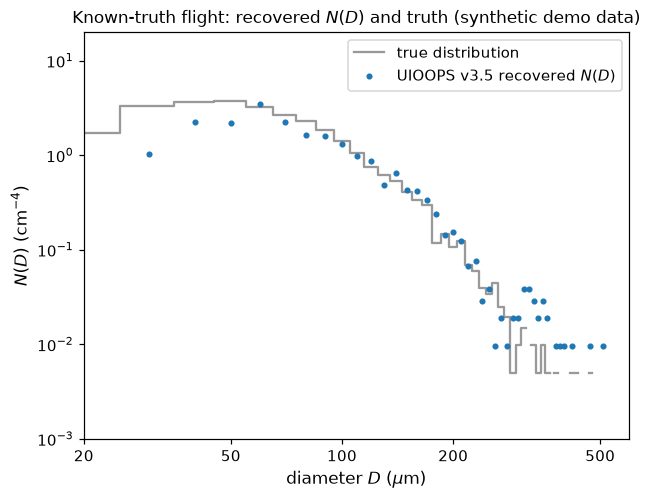

In [16]:
"""5g. Recovered N(D) beside the true droplet distribution."""
import matplotlib.pyplot as plt  # noqa: E402

fig, ax = plt.subplots()
true_hist = np.histogram(d_true_um, bins=edges_um)[0] / volume_cm3 / (dd_mm / 10.0)
true_hist[true_hist == 0] = np.nan          # an empty bin has no value on a log axis
ax.step(mid_mm * 1000, true_hist, where="mid", label="true distribution", color="0.6")
ax.plot(mid_mm[use] * 1000, conc.mean(axis=0)[use], "o", ms=3, label="UIOOPS v3.5 recovered $N(D)$")
ax.set(xscale="log", yscale="log", xlim=(20, 600), ylim=(1e-3, 20), xlabel=r"diameter $D$ ($\mu$m)",
       ylabel=r"$N(D)$ (cm$^{-4}$)")
ax.set_title("Known-truth flight: recovered $N(D)$ and truth (synthetic demo data)", fontsize=11)
ax.set_xticks([20, 50, 100, 200, 500], labels=["20", "50", "100", "200", "500"])
ax.minorticks_off()
ax.legend(fontsize=10)
plt.show()

*Figure 2. The known-truth synthetic flight: the true droplet distribution (grey steps) and the distribution UIOOPS v3.5 recovers from the rendered probe images (dots), over the bins used for the bulk quantities. In the smallest bins the recovered distribution falls below the truth, the optics loss described below.*

### What to take from this

The recovered numbers differ from the truth because of what the probe sees, not because of
the arithmetic above: droplets far from the object plane image larger than they are or not
at all, droplets at the array ends are clipped, and small droplets span only a few pixels.
Nt comes out low and the $D^3$-weighted numbers high on this flight. `scripts/truth_harness.py`
runs this comparison against the known truth; it does not attribute each droplet's loss to the
gate that removed it on the v3.5 chain.

## 6. Checking your own two products

1. **Align the clocks first.** A constant offset between the two products shifts every
   per-second comparison; see [03_clock_offsets.ipynb](../5_data_quality/03_clock_offsets.ipynb). With a best lag of a few
   seconds, compare cloud-leg composites rather than seconds.
2. **Put both products on one bin ladder** and apply one size cut to both before any moment.
3. **Use the mean distribution over the counted seconds** for every headline figure. Report the
   one-count quantum ratio and the positive-cell occupancy ratio beside any ratio, so a difference
   splits into sample volume and detection.
4. **Class every second by phase** before quoting LWC or an ice mass, and report per class.
   [10_check_the_phase_assumption.ipynb](../5_data_quality/10_check_the_phase_assumption.ipynb) shows the temperature check and, in its section 7, the
   per-phase moments of two products.
5. **Report Z in dBZ and every difference between products in dB.**
6. **Name, for every quoted number,** the flight, the product and its processing record, the size
   cut, the in-cloud rule and the number of seconds counted.

## References

- Gupta et al. (2021). *Atmos. Chem. Phys.*, 21, 4615-4635, doi:10.5194/acp-21-4615-2021.
- Hansen, J. E. and Travis, L. D. (1974). Light scattering in planetary atmospheres. *Space Sci.
  Rev.*, 16, 527-610. Eqs. (2.53)-(2.54): effective radius and effective variance.
- O'Brien, J., Gupta, S., McFarquhar, G., Poellot, M., Delene, D. and Griswold, J. Combined Cloud
  Microphysics Data Set for ORACLES (data-set readme, revision R1), Table 1: the formulas for
  $N_c$, $r_e$, LWC, rain rate, $Z$ and extinction.
- Gupta, S., McFarquhar, G. M., O'Brien, J. R., Poellot, M. R., Delene, D. J., Miller, R. M. and
  Small Griswold, J. D. (2022a). Factors affecting precipitation formation and precipitation
  susceptibility of marine stratocumulus with variable above- and below-cloud aerosol
  concentrations over the Southeast Atlantic. *Atmos. Chem. Phys.*, 22, 2769-2793,
  doi:10.5194/acp-22-2769-2022. Eqs. (5) and (8): precipitation rate and susceptibility.
- Gupta, S., McFarquhar, G. M., O'Brien, J. R., Poellot, M. R., Delene, D. J., Chang, I., Gao, L.,
  Xu, F. and Redemann, J. (2022b). In situ and satellite-based estimates of cloud properties and
  aerosol-cloud interactions over the southeast Atlantic Ocean. *Atmos. Chem. Phys.*, 22,
  12923-12943, doi:10.5194/acp-22-12923-2022. Eqs. (1)-(6): $R_e$, $V_e$, LWC, $\tau$ and the
  adiabatic relations.
- Rogers, R. R. and Yau, M. K. (1989). *A Short Course in Cloud Physics*, 3rd edn.,
  International Series in Natural Philosophy, Butterworth-Heinemann, 290 pp.,
  ISBN 9780750632157: the drop fall-speed relation $u(D)$ in $R_p$.
- Brown, P. R. A. and Francis, P. N. (1995). Improved measurements of the ice water content in
  cirrus using a total-water probe. *J. Atmos. Oceanic Technol.*, 12, 410-414. Eq. (3) and the
  text after it: the ice mass relation of section 2, with solid ice spheres below 100 um.

## What to try next

- Fit a gamma distribution to these size distributions, by least squares and by the method of
  moments, in [07_gamma_fitting](07_gamma_fitting.ipynb).
- Class each second by phase before quoting a water content:
  [10_check_the_phase_assumption](../5_data_quality/10_check_the_phase_assumption.ipynb).
- See how far the size definition moves these moments:
  [04_size_definition_sensitivity](04_size_definition_sensitivity.ipynb).